# Part 3: Multi-Window VaR Backtest

### Ramith Vaid | NTU Singapore

Part 2 scored the GARCH-normal and GARCH-t VaR models on a single 750-day window (October 2023 to October 2026), a mostly calm stretch, and its own write-up flagged that as a limit: one contiguous window, no crisis. This notebook repeats the same backtest on **three non-overlapping 750-day blocks** and adds a pooled test, so a conclusion about coverage does not rest on one slice of history.

**How the blocks are sized, and why.** The original plan was several windows in place of one 209-day window, but 209 (or 250) days expects only 2 to 2.5 breaches at 99%, too few for a coverage test to mean anything, so Part 2 moved to 750 days (7.5 expected breaches at 99%). Shrinking the blocks back below that would reintroduce the problem. So each block keeps Part 2's length of **750 trading days**, and the blocks are laid end to end, **aligned to the end of the data**, so the newest block is exactly Part 2's window and can be checked against it. The data has 3,213 daily returns and each daily refit needs the previous 750 days of training data, which leaves 2,463 days that can be scored: room for **three** 750-day blocks (2,250 days) and 213 left over, rather than four slightly shorter blocks with about 6 expected breaches at 99%. Per block that is 37.5 expected breaches at 95% and 7.5 at 99%. The pooled 2,250 days expect 112.5 and 22.5.

Everything else is Part 2's setup unchanged: both models refit every day on the previous 750 days, the same `rolling_normal_vs_t` function, the same `var_threshold`, Kupiec proportion-of-failures test, and Christoffersen independence and conditional-coverage tests, for both tickers at 95% and 99%. The only new code in `garch_utils.py` is appended (`block_slices`, `var_hits`, `coverage_row`).

**Data end date is pinned** to 2026-10-13 as in Part 2 so the notebook reproduces. This is roughly 2 x 2,250 GARCH fits per ticker, so it takes a while (tens of minutes).

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    rolling_normal_vs_t, var_threshold, kupiec_pof, christoffersen,
    block_slices, var_hits, coverage_row
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data (same tickers, range and pinned end date as Part 2)

In [2]:
TICKERS = {'JPM': 'JPMorgan Chase', '^GSPC': 'S&P 500'}
START = '2014-01-01'
END = '2026-10-14'  # exclusive: last row is 2026-10-13

log_returns = {}
for ticker, name in TICKERS.items():
    df = yf.download(ticker, start=START, end=END, progress=False)
    close = df['Close'].squeeze()
    log_returns[ticker] = np.log(close / close.shift(1)).dropna()
    r = log_returns[ticker]
    print(f'{name} ({ticker}): {len(r)} daily log returns, {r.index[0].date()} to {r.index[-1].date()}')

JPMorgan Chase (JPM): 3213 daily log returns, 2014-01-03 to 2026-10-13
S&P 500 (^GSPC): 3213 daily log returns, 2014-01-03 to 2026-10-13


## 2. Rolling normal and t refits over 2,250 test days

Same function as Part 2, with `test_size=2250` (three blocks of 750). The first scored day has 750 days of training data behind it, the same as every other day.

In [3]:
BLOCK_LEN, N_BLOCKS = 750, 3
rolling = {}
for ticker, name in TICKERS.items():
    print(f'Rolling normal + t refits for {name} ({ticker})...')
    rolling[ticker] = rolling_normal_vs_t(log_returns[ticker], train_window=750, test_size=BLOCK_LEN * N_BLOCKS)
    d = rolling[ticker]
    print(f'  {len(d)} test days, {d.index[0].date()} to {d.index[-1].date()}, median fitted nu = {d["nu"].median():.1f}')

Rolling normal + t refits for JPMorgan Chase (JPM)...


  2250 test days, 2017-10-30 to 2026-10-13, median fitted nu = 4.7
Rolling normal + t refits for S&P 500 (^GSPC)...


  2250 test days, 2017-10-30 to 2026-10-13, median fitted nu = 6.0


## 3. The blocks

Each block is 750 trading days. Realized volatility is the annualized standard deviation of the block's daily returns, to say what kind of period each block is.

In [4]:
slices = block_slices(len(rolling['JPM']), BLOCK_LEN, N_BLOCKS)
block_info = []
for label, sl in slices.items():
    d = rolling['JPM'].iloc[sl]
    row = {'block': label, 'start': d.index[0].date(), 'end': d.index[-1].date(), 'days': len(d)}
    for ticker in TICKERS:
        row[f'{ticker} realized vol (ann. %)'] = rolling[ticker].iloc[sl]['ret'].std() * np.sqrt(252)
        row[f'{ticker} worst day (%)'] = rolling[ticker].iloc[sl]['ret'].min()
    block_info.append(row)
block_df = pd.DataFrame(block_info)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 200)
print(block_df.to_string(index=False))

  block      start        end  days  JPM realized vol (ann. %)  JPM worst day (%)  ^GSPC realized vol (ann. %)  ^GSPC worst day (%)
block 1 2017-10-30 2020-10-21   750                      34.31             -16.21                        23.25               -12.77
block 2 2020-10-22 2023-10-16   750                      26.20              -6.34                        17.84                -4.42
block 3 2023-10-17 2026-10-13   750                      23.13              -7.78                        14.94                -6.16


## 4. VaR coverage by block

For each block, both models, both tickers, both levels: breaches against the expected count, the Kupiec test, and the Christoffersen independence and conditional-coverage tests. `block 3` is Part 2's window and should reproduce its 750-day table exactly.

In [5]:
LEVELS = [0.95, 0.99]
rows = []
for ticker in TICKERS:
    d_all = rolling[ticker]
    for level in LEVELS:
        p = 1 - level
        for model in ('normal', 't'):
            hits_all = var_hits(d_all, level, model)
            for label, sl in slices.items():
                d = d_all.iloc[sl]
                r = coverage_row(hits_all[sl], p)
                rows.append({'ticker': ticker, 'level': level, 'model': model, 'block': label,
                             'start': d.index[0].date(), 'end': d.index[-1].date(), **r})
block_cov = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
print(block_cov.drop(columns=['start', 'end']).to_string(index=False))

ticker  level  model   block  n_days  breaches  expected  breach_rate_%  nominal_%  kupiec_p  indep_p  cond_cov_p
   JPM  0.950 normal block 1     750        43    37.500          5.733      5.000     0.367    0.010       0.024
   JPM  0.950 normal block 2     750        34    37.500          4.533      5.000     0.552    0.072       0.166
   JPM  0.950 normal block 3     750        31    37.500          4.133      5.000     0.262    0.539       0.442
   JPM  0.950      t block 1     750        49    37.500          6.533      5.000     0.065    0.013       0.009
   JPM  0.950      t block 2     750        33    37.500          4.400      5.000     0.442    0.081       0.162
   JPM  0.950      t block 3     750        36    37.500          4.800      5.000     0.800    0.833       0.947
   JPM  0.990 normal block 1     750        14     7.500          1.867      1.000     0.033    0.257       0.054
   JPM  0.990 normal block 2     750         6     7.500          0.800      1.000     0

### Check against Part 2

Block 3 uses the same last 750 days and the same models, so its breach counts and Kupiec p-values should equal `part2_var_coverage.csv` (window "last 750 days").

In [6]:
p2 = pd.read_csv('part2_var_coverage.csv')
p2 = p2[p2['window'] == 'last 750 days']
chk = block_cov[block_cov['block'] == 'block 3'].merge(
    p2, on=['ticker', 'level', 'model'], suffixes=('_p3', '_p2'))
same = (chk['breaches_p3'] == chk['breaches_p2']).all() and np.allclose(chk['kupiec_p_p3'], chk['kupiec_p_p2'])
print('Block 3 reproduces Part 2 (breach counts and Kupiec p-values identical):', same)
print(chk[['ticker', 'level', 'model', 'breaches_p3', 'breaches_p2']].to_string(index=False))

Block 3 reproduces Part 2 (breach counts and Kupiec p-values identical): True
ticker  level  model  breaches_p3  breaches_p2
   JPM  0.950 normal           31           31
   JPM  0.950      t           36           36
   JPM  0.990 normal           19           19
   JPM  0.990      t           17           17
 ^GSPC  0.950 normal           42           42
 ^GSPC  0.950      t           45           45
 ^GSPC  0.990 normal           12           12
 ^GSPC  0.990      t           12           12


## 5. Pooled coverage across all 2,250 days

Pooling the three blocks gives a test with 22.5 expected breaches at 99% instead of 7.5. It treats the 2,250 days as one sequence, so it assumes breaches are independent across the block joins (the Christoffersen tests do not reject within blocks, which is the evidence for that). It mixes regimes, so a pooled pass can hide a block that failed, and a pooled fail can come from one bad block; read it with the per-block table, not instead of it.

In [7]:
prow = []
for ticker in TICKERS:
    d_all = rolling[ticker]
    for level in LEVELS:
        p = 1 - level
        for model in ('normal', 't'):
            hits = var_hits(d_all, level, model)
            prow.append({'ticker': ticker, 'level': level, 'model': model, **coverage_row(hits, p)})
pooled = pd.DataFrame(prow)
print(pooled.to_string(index=False))

ticker  level  model  n_days  breaches  expected  breach_rate_%  nominal_%  kupiec_p  indep_p  cond_cov_p
   JPM  0.950 normal    2250       108   112.500          4.800      5.000     0.661    0.108       0.249
   JPM  0.950      t    2250       118   112.500          5.244      5.000     0.598    0.134       0.284
   JPM  0.990 normal    2250        39    22.500          1.733      1.000     0.002    0.182       0.003
   JPM  0.990      t    2250        29    22.500          1.289      1.000     0.187    0.389       0.289
 ^GSPC  0.950 normal    2250       135   112.500          6.000      5.000     0.035    0.089       0.025
 ^GSPC  0.950      t    2250       143   112.500          6.356      5.000     0.005    0.190       0.008
 ^GSPC  0.990 normal    2250        47    22.500          2.089      1.000     0.000    0.355       0.000
 ^GSPC  0.990      t    2250        33    22.500          1.467      1.000     0.038    0.095       0.029


## 6. How many blocks fail, and a multiple-testing check

24 block-level Kupiec tests (2 tickers x 2 levels x 2 models x 3 blocks) at the 5% level would reject about 1.2 times by chance alone even if every model were exactly calibrated. A Holm adjustment across the 24 p-values says which rejections survive that.

In [8]:
def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

block_cov['kupiec_p_holm'] = holm(block_cov['kupiec_p'])
block_cov['rejects_5%'] = block_cov['kupiec_p'] < 0.05
block_cov['rejects_5%_holm'] = block_cov['kupiec_p_holm'] < 0.05
summary = (block_cov.groupby(['ticker', 'level', 'model'])
           .agg(blocks_rejected=('rejects_5%', 'sum'), blocks_rejected_holm=('rejects_5%_holm', 'sum'),
                total_breaches=('breaches', 'sum'), total_expected=('expected', 'sum'))
           .reset_index())
print(f"Block-level rejections at 5%: {int(block_cov['rejects_5%'].sum())} of {len(block_cov)} "
      f"(about {0.05 * len(block_cov):.1f} expected by chance); surviving Holm adjustment: {int(block_cov['rejects_5%_holm'].sum())}")
print()
print(summary.to_string(index=False))
print()
print('Christoffersen independence test, smallest p over all block/model/ticker/level cells:',
      round(block_cov['indep_p'].min(), 3), '(NaN cells, with too few breaches to test, are skipped)')

Block-level rejections at 5%: 7 of 24 (about 1.2 expected by chance); surviving Holm adjustment: 2

ticker  level  model  blocks_rejected  blocks_rejected_holm  total_breaches  total_expected
   JPM  0.950 normal                0                     0             108         112.500
   JPM  0.950      t                0                     0             118         112.500
   JPM  0.990 normal                2                     1              39          22.500
   JPM  0.990      t                1                     0              29          22.500
 ^GSPC  0.950 normal                0                     0             135         112.500
 ^GSPC  0.950      t                1                     0             143         112.500
 ^GSPC  0.990 normal                2                     1              47          22.500
 ^GSPC  0.990      t                1                     0              33          22.500

Christoffersen independence test, smallest p over all block/model/ticke

## 7. Were the breaches days when volatility exceeded the forecast?

Part 2 offered, but did not test, one explanation for the 99% JPM under-coverage: the breaches look like days when realized volatility exceeded the one-day forecast. If a model's one-day sigma is right on average, the standardized return `ret / sigma` has a standard deviation near 1. A value above 1 means the model under-forecast the size of daily moves in that block. Computed per block for each model's own sigma (the t model's sigma is the unit-variance conditional volatility, so it is on the same scale).

In [9]:
drows = []
for ticker in TICKERS:
    d_all = rolling[ticker]
    for label, sl in slices.items():
        d = d_all.iloc[sl]
        zn = d['ret'] / np.sqrt(d['sigma2_normal'])
        zt = d['ret'] / np.sqrt(d['sigma2_t'])
        drows.append({'ticker': ticker, 'block': label,
                      'sd(ret/sigma) normal': zn.std(), 'sd(ret/sigma) t': zt.std(),
                      'mean forecast vol (ann. %)': np.sqrt(d['sigma2_normal']).mean() * np.sqrt(252),
                      'realized vol (ann. %)': d['ret'].std() * np.sqrt(252),
                      'median nu': d['nu'].median()})
diag = pd.DataFrame(drows)
print(diag.to_string(index=False))

ticker   block  sd(ret/sigma) normal  sd(ret/sigma) t  mean forecast vol (ann. %)  realized vol (ann. %)  median nu
   JPM block 1                 1.082            1.024                      25.188                 34.307      3.866
   JPM block 2                 0.998            0.988                      26.505                 26.198      6.829
   JPM block 3                 1.030            1.030                      22.465                 23.129      4.164
 ^GSPC block 1                 1.081            1.041                      17.042                 23.246      4.013
 ^GSPC block 2                 1.006            1.001                      17.496                 17.838      6.859
 ^GSPC block 3                 0.997            0.994                      14.188                 14.938      7.953


## 8. Chart

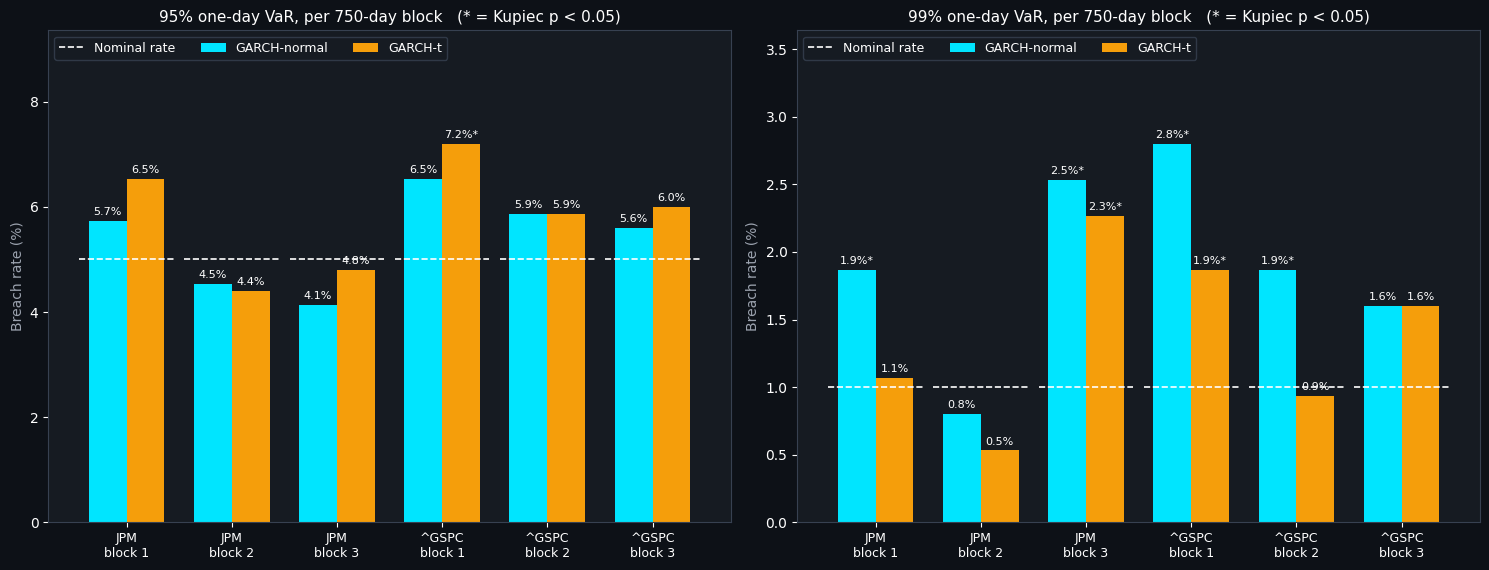

Saved chart_part3_multiwindow.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
fig.patch.set_facecolor('#0d1117')
groups = [(t, b) for t in TICKERS for b in slices]
x = np.arange(len(groups))
width = 0.36
for ax, level in zip(axes, LEVELS):
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
    sub = block_cov[block_cov['level'] == level]
    pad = 0.015 * sub['breach_rate_%'].max()
    ax.set_ylim(0, sub['breach_rate_%'].max() * 1.3)
    for off, model, color, label in ((-width/2, 'normal', '#00e5ff', 'GARCH-normal'), (width/2, 't', '#f59e0b', 'GARCH-t')):
        vals, flags = [], []
        for t, b in groups:
            r = sub[(sub.ticker == t) & (sub.block == b) & (sub.model == model)].iloc[0]
            vals.append(r['breach_rate_%'])
            flags.append(r['kupiec_p'] < 0.05)
        bars = ax.bar(x + off, vals, width, color=color, label=label)
        for bar, v, f in zip(bars, vals, flags):
            ax.text(bar.get_x() + bar.get_width()/2, v + pad,
                    f'{v:.1f}%' + ('*' if f else ''), ha='center', fontsize=8, color='white')
    for xi in x:
        ax.hlines(100 * (1 - level), xi - 0.45, xi + 0.45, colors='white', linestyles='--', linewidth=1.2,
                  label='Nominal rate' if xi == 0 else None)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{t}\n{b}' for t, b in groups], color='white', fontsize=9)
    ax.set_ylabel('Breach rate (%)', color='#9ca3af')
    ax.set_title(f'{int(level*100)}% one-day VaR, per 750-day block   (* = Kupiec p < 0.05)', color='white', fontsize=11)
    ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9, loc='upper left', ncol=3)
plt.tight_layout()
plt.savefig('chart_part3_multiwindow.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part3_multiwindow.png')

## 9. Summary and saved tables

In [11]:
block_cov.to_csv('part3_block_coverage.csv', index=False)
pooled.to_csv('part3_pooled_coverage.csv', index=False)
diag.to_csv('part3_block_diagnostics.csv', index=False)
block_df.to_csv('part3_blocks.csv', index=False)

print('=' * 70)
print('PART 3 SUMMARY: MULTI-WINDOW VAR BACKTEST')
print('=' * 70)
for label, sl in slices.items():
    d = rolling['JPM'].iloc[sl]
    print(f'{label}: {d.index[0].date()} to {d.index[-1].date()} ({len(d)} days)')
print()
print('Breaches per block, normal / t (Kupiec p in brackets):')
for ticker in TICKERS:
    for level in LEVELS:
        parts = []
        for label in slices:
            s = block_cov[(block_cov.ticker == ticker) & (block_cov.level == level) & (block_cov.block == label)]
            rn = s[s.model == 'normal'].iloc[0]; rt = s[s.model == 't'].iloc[0]
            parts.append(f'{label[-1]}: {rn["breaches"]} ({rn["kupiec_p"]:.3f}) / {rt["breaches"]} ({rt["kupiec_p"]:.3f})')
        exp = s.iloc[0]['expected']
        print(f'  {ticker} {int(level*100)}% [exp {exp}]  ' + '   '.join(parts))
print()
print('Pooled 2,250 days:')
for _, r in pooled.iterrows():
    print(f'  {r["ticker"]} {int(r["level"]*100)}% {r["model"]:<6} {r["breaches"]:>3} vs {r["expected"]} expected, Kupiec p = {r["kupiec_p"]:.4f}')
print()
print('Files saved: chart_part3_multiwindow.png, part3_block_coverage.csv, part3_pooled_coverage.csv, part3_block_diagnostics.csv, part3_blocks.csv')

PART 3 SUMMARY: MULTI-WINDOW VAR BACKTEST
block 1: 2017-10-30 to 2020-10-21 (750 days)
block 2: 2020-10-22 to 2023-10-16 (750 days)
block 3: 2023-10-17 to 2026-10-13 (750 days)

Breaches per block, normal / t (Kupiec p in brackets):
  JPM 95% [exp 37.5]  1: 43 (0.367) / 49 (0.065)   2: 34 (0.552) / 33 (0.442)   3: 31 (0.262) / 36 (0.800)
  JPM 99% [exp 7.5]  1: 14 (0.033) / 8 (0.856)   2: 6 (0.568) / 4 (0.159)   3: 19 (0.000) / 17 (0.003)
  ^GSPC 95% [exp 37.5]  1: 49 (0.065) / 54 (0.009)   2: 44 (0.289) / 44 (0.289)   3: 42 (0.459) / 45 (0.223)
  ^GSPC 99% [exp 7.5]  1: 21 (0.000) / 14 (0.033)   2: 14 (0.033) / 7 (0.853)   3: 12 (0.129) / 12 (0.129)

Pooled 2,250 days:
  JPM 95% normal 108 vs 112.5 expected, Kupiec p = 0.6613
  JPM 95% t      118 vs 112.5 expected, Kupiec p = 0.5975
  JPM 99% normal  39 vs 22.5 expected, Kupiec p = 0.0015
  JPM 99% t       29 vs 22.5 expected, Kupiec p = 0.1874
  ^GSPC 95% normal 135 vs 112.5 expected, Kupiec p = 0.0346
  ^GSPC 95% t      143 vs 112.5